In [10]:
import pandas as pd

In [13]:
df = pd.read_csv(r'C:\Users\Shree\Downloads\titanic\train.csv')

In [14]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [15]:
df.shape

(891, 12)

In [17]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


## Part 2 

**1. Is this supervised or unsupervised?**

This is a **Supervised Learning** problem because the dataset contains a target variable named `Survived`.

**2. Is it classification or regression?**

This is a **Classification** problem because we predict whether a passenger survived or not.

**3. What is the target variable?**

The target variable is `Survived`.

- 0 = Did not survive
- 1 = Survived

**4. What does success look like?**

Success means building a Machine Learning model that can correctly predict whether a passenger survived or not based on passenger information.

## Part 3 — Choose an Algorithm

### 1. Logistic Regression
Logistic Regression is used for classification problems. It predicts whether a passenger survived or not.

### 2. Decision Tree
Decision Tree uses a tree-like structure to make decisions. It can predict survival based on passenger information.

### 3. K-Nearest Neighbors (KNN)
KNN predicts the result by comparing a passenger with similar passengers in the dataset.

### Selected Algorithm: Logistic Regression

I selected Logistic Regression because our target variable (Survived) has two classes: 0 and 1. It is a suitable algorithm for binary classification problems.

In [21]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [22]:
(df.isnull().sum() / len(df)) * 100

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64

##  part 4 - Exploratory Data Analysis (EDA)
####  Defining Plot 

## Age Distribution

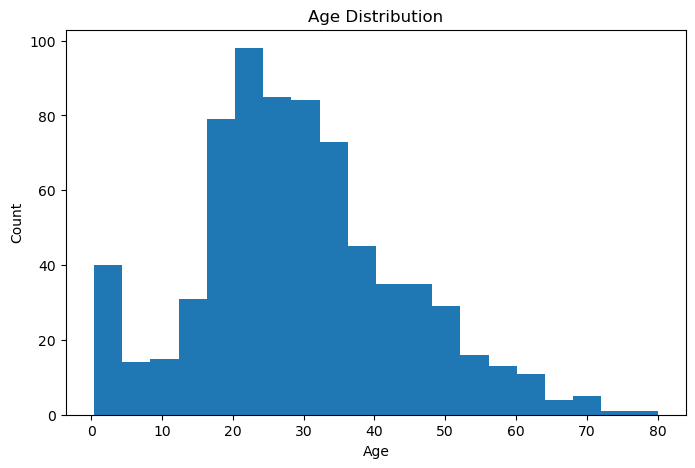

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df['Age'], bins=20)
plt.xlabel('Age')
plt.ylabel('Count')
plt.title('Age Distribution')
plt.show()

## Survival Count

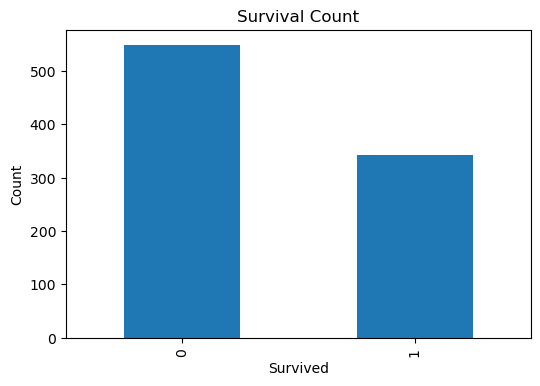

In [24]:
plt.figure(figsize=(6,4))
df['Survived'].value_counts().plot(kind='bar')
plt.xlabel('Survived')
plt.ylabel('Count')
plt.title('Survival Count')
plt.show()

## Train-Test Split (80:20)

In [29]:
X = df.drop('Survived', axis=1)
y = df['Survived']

##### X = Independent Features (passenger info)
##### y = Dependent Variable (survived)

### Train-Test Split

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split (X, y, test_size=0.20, random_state=42)

### CHeck shape 

In [27]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(712, 11)
(179, 11)
(712,)
(179,)


### Why do we split data before preprocessing?

We split the data before preprocessing to avoid data leakage. This ensures that the model learns only from training data. The test data remains separate and is used to evaluate the model on unseen data.

### Identify Features

In [28]:
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns

categorical_cols = X.select_dtypes(include=['object']).columns

print("Numerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

Numerical Columns:
Index(['PassengerId', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')

Categorical Columns:
Index(['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'], dtype='object')


# part 5 - Data Preprocessing

In [30]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']

X = df[features]
y = df['Survived']

X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


In [31]:
X.isnull().sum()

Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

In [33]:
X = df[features].copy()
y = df['Survived']

In [34]:
from sklearn.impute import SimpleImputer

num_imputer = SimpleImputer(strategy='median')

X.loc[:, 'Age'] = num_imputer.fit_transform(X[['Age']]).ravel()

In [35]:
X.isnull().sum()

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    2
dtype: int64

In [36]:
cat_imputer = SimpleImputer(strategy='most_frequent')

X.loc[:, 'Embarked'] = cat_imputer.fit_transform(X[['Embarked']]).ravel()

In [37]:
X.isnull().sum()

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

## Encoding Categorical Data

In [39]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

onehot = OneHotEncoder(handle_unknown='ignore')

ordinal = OrdinalEncoder(categories=[[1, 2, 3]])

In [40]:
encoded_data = onehot.fit_transform(X[['Sex', 'Embarked']])

encoded_df = pd.DataFrame(
    encoded_data.toarray(),
    columns=onehot.get_feature_names_out(['Sex', 'Embarked'])
)

encoded_df.head()

,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0.0,1.0,0.0,0.0,1.0
1,1.0,0.0,1.0,0.0,0.0
2,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0


## Ordinal Encoding — Pclass

In [41]:
X['Pclass_encoded'] = ordinal.fit_transform(X[['Pclass']])

X[['Pclass', 'Pclass_encoded']].head()

,Pclass,Pclass_encoded
0,3,2.0
1,1,0.0
2,3,2.0
3,1,0.0
4,3,2.0


## StandardScaler

In [43]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

num_cols = ['Age', 'SibSp', 'Parch', 'Fare']

X[num_cols] = scaler.fit_transform(X[num_cols])

In [44]:
X[num_cols].head()

,Age,SibSp,Parch,Fare
0,-0.565736,0.432793,-0.473674,-0.502445
1,0.663861,0.432793,-0.473674,0.786845
2,-0.258337,-0.474545,-0.473674,-0.488854
3,0.433312,0.432793,-0.473674,0.420730
4,0.433312,-0.474545,-0.473674,-0.486337


### Why is Scaling Important?

Scaling is important because numerical features may have different ranges.
StandardScaler transforms numerical data to have a mean of 0 and a standard deviation of 1.

### Why do we use Encoding?

Encoding converts categorical data into numerical format so that Machine Learning algorithms can understand it.

- OneHotEncoder is used for unordered categorical data.
- OrdinalEncoder is used for ordered categorical data.

# Part 6 — ColumnTransformer and Pipeline

In [45]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']

X = df[features].copy()
y = df['Survived']

In [46]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

In [47]:
print(X_train.shape)
print(X_test.shape)

(712, 7)
(179, 7)


In [48]:
num_cols = ['Age', 'SibSp', 'Parch', 'Fare']

cat_cols = ['Sex', 'Embarked']

ordinal_cols = ['Pclass']

### Numerical Pipeline

In [50]:
# For NUmerical columns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [51]:
#Categorical Pipeline
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [52]:
# Ordinal Pipeline
from sklearn.preprocessing import OrdinalEncoder

ordinal_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(categories=[[1, 2, 3]]))
])

In [53]:
# ColumnTransformer
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols),
    ('ord', ordinal_pipeline, ordinal_cols)
])

In [54]:
# Machine Learning Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression())
])

In [55]:
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### Why does Pipeline prevent Data Leakage?

A Pipeline prevents data leakage by fitting preprocessing steps only on the training data.

The test data is transformed using the preprocessing steps learned from the training data. This ensures fair model evaluation.

# Part 7 — Model Evaluation

In [56]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[0 0 0 1 1 1 1 0 1 1]


In [57]:
# Accuracy Score
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Accuracy: 0.8100558659217877
Accuracy Percentage: 81.00558659217877


In [59]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.86      0.84       105
           1       0.79      0.74      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



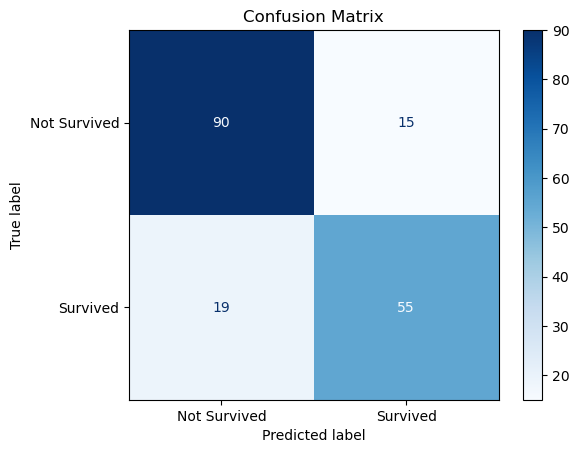

In [60]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Survived', 'Survived']
)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

### Confusion Matrix Interpretation

The confusion matrix shows the correct and incorrect predictions made by the model.

- True Negative: 90
- False Positive: 15
- False Negative: 19
- True Positive: 55

The model correctly predicted 145 out of 179 passengers.

### Is the Model Good?

The Logistic Regression model achieved 81.01% accuracy.
It performs reasonably well, but it needs improvement in identifying survived passengers because the recall for class 1 is 74%.

### How Can We Improve the Model?

- Try different Machine Learning algorithms.
- Perform feature engineering.
- Tune model parameters.
- Improve feature selection.

In [61]:
import joblib

joblib.dump(model, 'titanic_model.pkl')

print("Model saved successfully!")

Model saved successfully!
